# Phase 05 · Comparative evaluation

## The three wirings side by side on the auditory task

This notebook brings every metric of the project together and decides, with statistics, which of the three wirings solves the task best and at what cost. It runs no simulation. It reads the results that the scripts of phase 04 stored, the operating point of phase 03 and the contact-threshold sweep.

The three networks share the number of neurons and of connections of each sign, and the weight distribution. They also share the input layer, the stimuli, the neuron model, the plasticity rule, the readout and the operating point. They differ **only in how they are wired**.

| Wiring | What it keeps from the connectome |
|---|---|
| **Connectome** | the real wiring (FlyWire v783) |
| Erdős–Rényi | only the number of neurons and of connections |
| Configuration model | also, almost exactly, the degree sequence of every neuron |

The second control is the strict one. If the biological network beats it, the advantage cannot come from a few neurons that concentrate many connections.

Our evaluation objective is to compare the spiking networks with one another in accuracy, learning speed, spike efficiency, selectivity and weight stability. The notebook follows that list, one section per measure, and closes with robustness checks, a verdict and the conclusions.

1. **Classification accuracy** and its statistical significance
2. **The topology × plasticity interaction**
3. **Convergence speed** of the readout
4. **Spike efficiency**, the proxy for energy cost
5. **Latency**, accuracy against integration time
6. **Difficulty gradient** by pair of songs
7. **Selectivity and coverage** of the representation
8. **Weight stability** after learning
9. **Robustness** to seeds, channel mappings and contact threshold

### Background for readers new to the project

The project asks whether a spiking network wired like an auditory circuit of the fruit fly learns a sound task better than networks of the same size with artificial wiring. The circuit is that of **Johnston's organ** (JO), the fly's ear, taken from the FlyWire **connectome**, the map of all the neurons of the fly brain and of the connections between them (Dorkenwald et al., 2024). Phase 02 extracted it as a graph of 1,239 neurons and 20,059 connections. The two control networks keep its size. An **Erdős–Rényi** graph places the same number of connections of each sign at random (Erdős & Rényi, 1959). A **configuration model** also keeps how many connections enter and leave each neuron, its degree (Molloy & Reed, 1995; Newman et al., 2001).

In a **spiking neural network** (SNN) neurons communicate with brief electrical events called **spikes**. Ours are leaky integrate-and-fire neurons. Each one adds up its input current, leaks it slowly and fires when its voltage crosses a threshold. The networks learn with **spike-timing-dependent plasticity** (STDP), a local rule that strengthens a connection when the sending neuron fires just before the receiving one and weakens it when it fires just after (Song et al., 2000). **Winner-take-all** (WTA) inhibition holds the network back when many neurons fire at once, so that a few of them specialize.

The sound is the **courtship song** of the male fly, a train of brief song pulses. The time between pulses, the **inter-pulse interval** (IPI), is one of the cues a female uses to recognize males of her species (Bennet-Clark & Ewing, 1969). The task is to tell apart five songs whose IPIs are 25, 35, 45, 55 and 65 ms. We impose it as a proxy task on this first stage of the auditory pathway. In the fly, selectivity for the interval appears further downstream (Baker et al., 2022).

A **linear readout**, a logistic regression (Pedregosa et al., 2011), names the song from the number of spikes each neuron fired. It reads the 1,116 neurons that receive no direct input. Before comparing networks we measured the **input-only ceiling**, the accuracy of the same readout applied to the 123 input neurons alone. Whatever a network achieves above that ceiling is computed by the network.

The design has six experimental **arms**, the three wirings each run with static weights and with STDP + WTA. Each arm is repeated with several **seeds**, the numbers that fix the random generators so that a run can be repeated exactly. The arms with plasticity use fifteen seeds and the static arms five. All six were calibrated in phase 03 to the same **operating point**, a mean firing rate of 10 Hz before learning.

### How the comparison is measured

The main measure is **five-class accuracy**, the fraction of test presentations whose song the readout names correctly among the five. Guessing would get one in five right, so its **chance level** is 0.200. Section 6 uses a second measure, **pairwise accuracy**, where the readout only has to tell two songs apart. That is an easier question, and its chance level is 0.500. The two scales cannot be compared with each other. Each number has to be read against its own chance level, and we never set a pairwise accuracy next to a five-class one as if they measured the same thing.

Topology and plasticity are the two factors of the design. There is an **interaction** between them when the effect of one depends on the level of the other. Here the question is whether STDP helps every wiring by the same amount, or only some of them.

Means are reported ± the standard deviation across seeds, computed with the sample formula. A **paired comparison** sets two arms side by side seed by seed, so that the random draws are shared and only the factor of interest changes. We test it with a two-sided paired t-test on the seeds the two arms share, which gives five pairs when a static arm is involved and fifteen when both arms learn. The **p-value** is the probability of seeing a difference at least this large if there were none, and we call a difference significant when p < 0.05. A one-way **ANOVA** (analysis of variance) asks whether the mean accuracies of the three wirings differ within one plasticity condition. The **effect size** is Cohen's d, the difference between two means in units of their pooled standard deviation (Cohen, 1988/2013). Here the pooled variance is the average of the population variances of the two arms. The difference Δ and d use every seed of each arm, while the t-test uses only the shared ones. The p-values are not corrected for multiple comparisons. The tests use SciPy (Virtanen et al., 2020).

The other measures are defined in their sections. **Convergence** is the test accuracy of the readout as a function of how many training presentations it has seen. **Latency** is accuracy as a function of the **integration window**, the length of the response that the readout counts, from 25 to 500 ms; the main results use 250 ms. **Spike efficiency** is the number of **spikes per correct classification**, all the spikes the network fires during the test divided by the number of correct answers. The representation is described by **selectivity**, the population sparseness of the response of the readout neurons, and by **coverage**, the percentage of readout neurons that fire at all. Weight stability is described by the **mean absolute weight change** |Δw| and by the **drift** of the mean weight over the last 20 % of training. Finally, three **robustness** controls vary the seed, the mapping of filterbank channels onto input neurons and the **contact threshold**, the minimum number of synaptic contacts a connection needs to be kept.

## 0. Environment and data

The cell loads the subgraph, the operating point of phase 03 and the stored results of phase 04 (`results.json` and `extra_seeds.json`, which `load_results` joins). `F` keeps the 60 runs of the six arms of the design. The runs with other channel mappings stay in `ALL_RUNS` and come back in Section 9.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent))
from snnlib import evaluation as E, graph, FIGURES
from snnlib.evaluation import IPIS, PAIRS, WINDOWS_MS

FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':150, 'savefig.bbox':'tight',
                     'axes.titleweight':'bold', 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False})

# Palette: one color per topology, light shade for static and dark shade for plasticity
DARK  = {'connectome':'#1F6F8B', 'er':'#C0492B', 'configuration':'#2E8B6F'}
LIGHT = {'connectome':'#9CC6D6', 'er':'#E8A99B', 'configuration':'#A6D5C4'}
NAME  = {'connectome':'Connectome', 'er':'Erdős–Rényi', 'configuration':'Configuration model'}
TOPOS = ['connectome', 'er', 'configuration']
GRAY  = '#8A948F'

C = graph.load()
OP = json.loads((Path('..')/'03-data-preparation'/'outputs'/'operating_point.json').read_text())
ALL_RUNS = E.load_results()
F = ALL_RUNS[ALL_RUNS.arm.isin(OP['arms'])].copy()
CHANCE = 1/len(IPIS)
CEILING = F.input_accuracy.mean()

print(f'Network: {C.N} neurons · {len(C.pre):,} connections ({int(C.raw_weight.sum()):,} synaptic contacts) · {C.N_input} input')
print(f'Task: {len(IPIS)} inter-pulse intervals {IPIS} ms')
print(f'Chance = {CHANCE:.3f} · input-only ceiling = {CEILING:.3f}')
print(f'Runs: {len(F)} ({F.groupby(["topology","stdp"]).size().min()}–'
      f'{F.groupby(["topology","stdp"]).size().max()} seeds per arm)')

Network: 1239 neurons · 20,059 connections (338,013 synaptic contacts) · 123 input
Task: 5 inter-pulse intervals [25, 35, 45, 55, 65] ms
Chance = 0.200 · input-only ceiling = 0.223
Runs: 60 (5–15 seeds per arm)


The network has 1,239 neurons and 20,059 connections, formed by 338,013 synaptic contacts, with 123 input neurons. With five classes chance is 0.200, and the input-only ceiling, averaged over the 60 runs, is 0.223. The static arms have 5 seeds each and the plastic arms 15.

### A note on the input-only ceiling

Before comparing architectures we need to know how much the input layer already solves on its own. If the task were solved before the signal entered the circuit, the networks could only degrade it, and the comparison would not measure any computation.

Here that ceiling is **0.223 against a chance level of 0.200**, the mean over the sixty runs that the cell above prints. The input barely beats chance. **Any accuracy above that value is computed by the network**, and every experiment of the project reports this check.

Over the five seeds of the static arms alone the ceiling is 0.226, and the single measurement in Section 5 of the [audio-encoding notebook](../04-modeling/01-audio-encoding.ipynb) gives 0.250. The three values say the same thing. They differ because each comes from a small sample.

## 1. Classification accuracy

This is the main measure. The readout is trained on the responses of the network with its weights frozen, and it is tested on new random draws of the songs that it has never seen.

In [2]:
def arm(t, stdp, col='accuracy'):
    return F[(F.topology==t)&(F.stdp==stdp)].sort_values('seed')[col].values

summary = (F.groupby(['topology','stdp'])
             .agg(n=('accuracy','size'), accuracy=('accuracy','mean'),
                  sd=('accuracy','std'), rate=('mean_rate_hz','mean'),
                  spikes_per_correct=('spikes_per_correct','mean'),
                  selectivity=('selectivity','mean'),
                  coverage=('coverage_pct','mean'))
             .round(4).reset_index())
summary['network'] = summary.topology.map(NAME) + summary.stdp.map({True:' + STDP', False:', static'})
summary[['network','n','accuracy','sd','rate','spikes_per_correct','selectivity','coverage']]

,network,n,accuracy,sd,rate,spikes_per_correct,selectivity,coverage
0,"Configuration model, static",5,0.6040,0.0503,10.3203,5325.3870,0.9015,21.8471
1,Configuration model + STDP,15,0.7680,0.1484,21.5426,9209.2473,0.9263,11.1763
2,"Connectome, static",5,0.5660,0.0820,10.3825,5784.2426,0.9127,19.1550
3,Connectome + STDP,15,0.8753,0.0387,17.7359,6277.6494,0.9522,5.8511
4,"Erdős–Rényi, static",5,0.4440,0.0568,12.7422,9234.8145,0.8699,30.2371
5,Erdős–Rényi + STDP,15,0.4427,0.0799,33.9374,25175.1348,0.9150,11.8341


The table is sorted alphabetically by wiring (configuration, connectome, er). The connectome with STDP + WTA reaches the highest accuracy, 0.875 ± 0.039 over fifteen seeds. The configuration model with STDP follows at 0.768 ± 0.148, a much wider spread, and the static arms come well below. Erdős–Rényi stays at 0.444 without plasticity and 0.443 with it.

The column `rate` is the mean firing rate of the network during the test, in Hz. Plasticity raises it in every wiring, from about 10 Hz in the static arms to 17.7359 Hz in the connectome, 21.5426 Hz in the configuration model and 33.9374 Hz in Erdős–Rényi. Accuracy therefore has to be read together with `spikes_per_correct`, the spikes per correct classification of Section 4. The columns `selectivity` and `coverage` belong to Section 7.

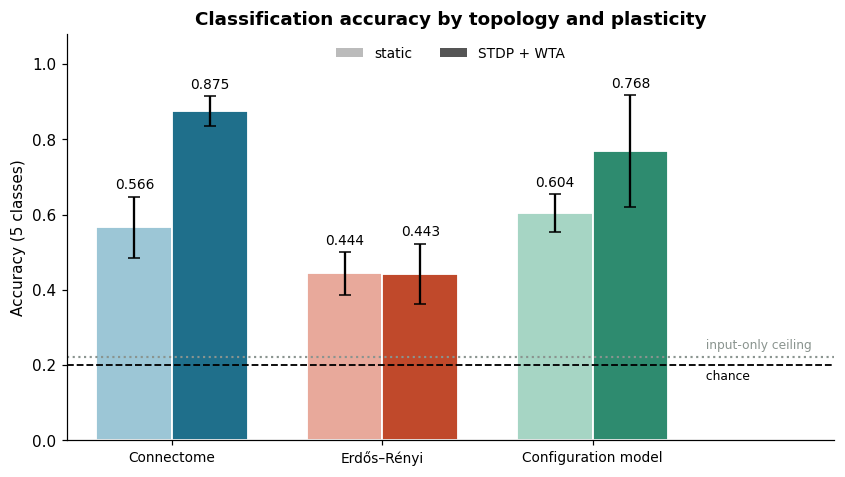

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(3); an = 0.36
for k, stdp in enumerate([False, True]):
    m = [arm(t, stdp).mean() for t in TOPOS]
    s = [arm(t, stdp).std(ddof=1) for t in TOPOS]
    ax.bar(x + (k-0.5)*an, m, an, yerr=s, capsize=4,
           color=[(LIGHT if not stdp else DARK)[t] for t in TOPOS],
           edgecolor='white', linewidth=1.2)
    for i, (mi, si) in enumerate(zip(m, s)):
        ax.text(i+(k-0.5)*an, mi+si+0.02, f'{mi:.3f}', ha='center', fontsize=9)
ax.axhline(CHANCE, color='k', ls='--', lw=1.2)
ax.axhline(CEILING, color=GRAY, ls=':', lw=1.4)
ax.text(2.52, CHANCE-0.012, ' chance', va='top', fontsize=8)
ax.text(2.52, CEILING+0.012, ' input-only ceiling', va='bottom', fontsize=8, color=GRAY)
ax.set_xticks(x); ax.set_xticklabels([NAME[t] for t in TOPOS], fontsize=9)
ax.set_ylabel('Accuracy (5 classes)'); ax.set_ylim(0, 1.08); ax.set_xlim(-0.5, 3.15)
ax.legend(handles=[Patch(facecolor='#BBBBBB', label='static'),
                   Patch(facecolor='#555555', label='STDP + WTA')],
          loc='upper center', ncol=2, fontsize=9, frameon=False)
ax.set_title('Classification accuracy by topology and plasticity')
fig.savefig(FIGURES/'05-accuracy-by-topology.png'); plt.show()

Light bars are the static arms and dark bars the arms with STDP + WTA, with error bars of ± one standard deviation across seeds. The dashed line marks chance and the dotted line the input-only ceiling. Plasticity lifts the connectome far above its static version. It lifts the configuration model less, with a much wider spread, and leaves Erdős–Rényi where it was.

### Statistical contrasts

The cell sets the connectome with STDP against each of the other five arms. For each contrast it prints the difference in mean accuracy (Δ), the t statistic of the paired test, the p-value and Cohen's d. A one-way ANOVA then asks whether the three wirings differ within each plasticity condition.

In [4]:
print('CONNECTOME + STDP against each alternative (paired t-test by seed)\n')
print(f'{"comparison":38s}{"Δ":>9}{"t":>8}{"p":>10}{"Cohen\'s d":>12}  verdict')
ref = arm('connectome', True)
rows = []
for t, stdp, name in [('connectome',False,'connectome without STDP'),
                      ('er',True,'Erdős–Rényi + STDP'), ('er',False,'Erdős–Rényi, static'),
                      ('configuration',True,'configuration model + STDP'),
                      ('configuration',False,'configuration model, static')]:
    o = arm(t, stdp); n = min(len(ref), len(o))
    tt, p = stats.ttest_rel(ref[:n], o[:n])
    d = ref.mean() - o.mean()
    coh = d/np.sqrt((ref.var()+o.var())/2)   # Cohen's d with the population variance (ddof=0)
    verdict = 'CONNECTOME BETTER' if (p<0.05 and d>0) else ('worse' if p<0.05 else 'no difference')
    rows.append(dict(comparison=name, delta=d, p=p, cohen=coh, verdict=verdict))
    print(f'{name:38s}{d:+9.3f}{tt:8.2f}{p:10.5f}{coh:12.2f}  {verdict}')
print()
print('ANOVA of the effect of topology, within each plasticity condition:')
for stdp in [False, True]:
    g = [arm(t, stdp) for t in TOPOS]
    r = stats.f_oneway(*g)
    print(f'  {"STDP + WTA" if stdp else "static":12s}  F = {r.statistic:5.2f}   p = {r.pvalue:.5f}')

# Correction for multiple comparisons over the five contrasts above
print()
print('Correction for multiple comparisons over the five contrasts:')
ranked = sorted(rows, key=lambda r: r['p'])
holm_ok = True
for k, r in enumerate(ranked):
    holm_ok = holm_ok and r['p'] < 0.05 / (len(ranked) - k)
    print(f'  {r["comparison"]:38s}Bonferroni p = {min(1, r["p"] * len(ranked)):.4f}   '
          f'Holm: {"significant" if holm_ok else "not significant"}')

# The decisive contrast on the first five seeds and on the ten seeds added later
print()
print('Connectome + STDP against configuration model + STDP, by batch of seeds:')
a_, b_ = arm('connectome', True), arm('configuration', True)
for part, name in [(slice(0, 5), 'seeds 0-4 (first batch)'), (slice(5, None), 'seeds 5-14 (added)')]:
    print(f'  {name:26s}Δ = {(a_[part] - b_[part]).mean():+.3f}   '
          f'p = {stats.ttest_rel(a_[part], b_[part]).pvalue:.4f}')

CONNECTOME + STDP against each alternative (paired t-test by seed)

comparison                                    Δ       t         p   Cohen's d  verdict
connectome without STDP                  +0.309    5.69   0.00471        5.31  CONNECTOME BETTER
Erdős–Rényi + STDP                       +0.433   19.84   0.00000        7.14  CONNECTOME BETTER
Erdős–Rényi, static                      +0.431   15.08   0.00011        9.67  CONNECTOME BETTER
configuration model + STDP               +0.107    2.72   0.01671        1.02  CONNECTOME BETTER
configuration model, static              +0.271    7.67   0.00156        6.56  CONNECTOME BETTER

ANOVA of the effect of topology, within each plasticity condition:
  static        F =  8.39   p = 0.00525
  STDP + WTA    F = 76.38   p = 0.00000

Correction for multiple comparisons over the five contrasts:
  Erdős–Rényi + STDP                    Bonferroni p = 0.0000   Holm: significant
  Erdős–Rényi, static                   Bonferroni p = 0.0006   Holm

The connectome with STDP beats each of the other five arms with p < 0.05. Against Erdős–Rényi with STDP the difference is +0.433 (t = 19.84, d = 7.14); the cell prints p = 0.00000 because the value is below 0.00001. Against the configuration model with STDP it is +0.107 (t = 2.72, p = 0.01671, d = 1.02).

That last contrast is the decisive one. The configuration model keeps, almost exactly, the degree sequence of the connectome and only rewires where the connections go, so it rules out the most obvious explanation, that the advantage comes from a few highly connected neurons. A recent preprint, not yet peer reviewed, argues that topology advantages reported for connectome-constrained networks can disappear against such degree-preserving controls (Dhiman, 2026). With the first five seeds this difference was +0.156 and not significant (p = 0.17). With fifteen it is. Those ten seeds were added after the first result, and on them alone the connectome still leads, by +0.083, with p = 0.0593.

The p-values of the table are not corrected for multiple comparisons. The cell also applies two corrections to the five contrasts. The Holm procedure keeps all five significant, while the stricter Bonferroni correction raises the decisive one to 0.0836.

The ANOVA finds an effect of the wiring in both conditions, with F = 8.39 (p = 0.00525) among the static arms and F = 76.38 (p < 0.00001) among the plastic ones.

## 2. The interaction between topology and plasticity

This is the central finding of the project. The same learning rule, with the same parameters and on networks of identical size, has very different effects depending on the wiring it works on. The cell compares each wiring with and without plasticity, seed by seed, and draws the change.

topology                        static    STDP + WTA         Δ         p
Connectome                       0.566         0.875    +0.309   0.00471
Erdős–Rényi                      0.444         0.443    -0.001   0.70578
Configuration model              0.604         0.768    +0.164   0.21314

Plasticity gives a significant improvement only on the biological wiring.

Interaction test (gain of the connectome minus gain of each control, paired by seed):
  connectome vs Erdős–Rényi           Δ gain = +0.330   p = 0.0114
  connectome vs Configuration model   Δ gain = +0.194   p = 0.0988


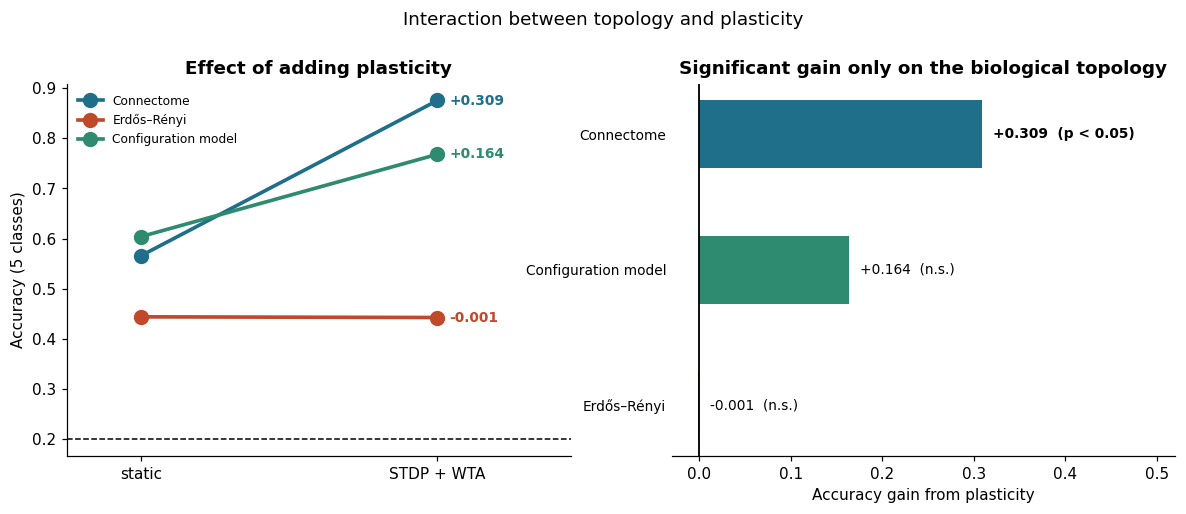

In [5]:
print(f'{"topology":26s}{"static":>12}{"STDP + WTA":>14}{"Δ":>10}{"p":>10}')
delta = {}
for t in TOPOS:
    a, b = arm(t, False), arm(t, True)
    n = min(len(a), len(b))
    tt, p = stats.ttest_rel(b[:n], a[:n])
    delta[t] = (b.mean()-a.mean(), p)
    print(f'{NAME[t]:26s}{a.mean():12.3f}{b.mean():14.3f}{b.mean()-a.mean():+10.3f}{p:10.5f}')
print()
print('Plasticity gives a significant improvement only on the biological wiring.')

# Direct test of the interaction: gain of the connectome against the gain of each control,
# paired on the seeds that the static and the plastic arm share
print()
print('Interaction test (gain of the connectome minus gain of each control, paired by seed):')
gain = {t: arm(t, True)[:len(arm(t, False))] - arm(t, False) for t in TOPOS}
for t in ['er', 'configuration']:
    tt, p = stats.ttest_rel(gain['connectome'], gain[t])
    print(f'  connectome vs {NAME[t]:22s}Δ gain = {(gain["connectome"] - gain[t]).mean():+.3f}   p = {p:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for t in TOPOS:
    a, b = arm(t, False).mean(), arm(t, True).mean()
    ax[0].plot([0, 1], [a, b], 'o-', color=DARK[t], lw=2.4, ms=9, label=NAME[t])
    ax[0].annotate(f'{b-a:+.3f}', (1, b), xytext=(8, 0), textcoords='offset points',
                   va='center', fontsize=9, color=DARK[t], fontweight='bold')
ax[0].axhline(CHANCE, color='k', ls='--', lw=1)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(['static', 'STDP + WTA'])
ax[0].set_xlim(-0.25, 1.45); ax[0].set_ylabel('Accuracy (5 classes)')
ax[0].legend(fontsize=8, frameon=False); ax[0].set_title('Effect of adding plasticity')

order_by_delta = sorted(TOPOS, key=lambda t: delta[t][0])
d = [delta[t][0] for t in order_by_delta]
ax[1].barh(range(3), d, color=[DARK[t] for t in order_by_delta], height=.5)
ax[1].axvline(0, color='k', lw=1.2)
for i, t in enumerate(order_by_delta):
    sig = 'p < 0.05' if delta[t][1] < 0.05 else 'n.s.'
    ax[1].text(max(delta[t][0], 0) + 0.012, i, f'{delta[t][0]:+.3f}  ({sig})',
               va='center', ha='left', fontsize=9,
               fontweight='bold' if delta[t][1] < 0.05 else 'normal')
ax[1].set_yticks(range(3)); ax[1].set_yticklabels([NAME[t] for t in order_by_delta], fontsize=9)
ax[1].set_xlim(-0.03, 0.52); ax[1].set_xlabel('Accuracy gain from plasticity')
ax[1].spines['left'].set_visible(False); ax[1].tick_params(axis='y', length=0)
ax[1].set_title('Significant gain only on the biological topology')
fig.suptitle('Interaction between topology and plasticity', y=1.03)
fig.savefig(FIGURES/'05-topology-plasticity-interaction.png'); plt.show()

STDP improves the connectome by +0.309 (p = 0.00471). It improves the configuration model by +0.164, which is not significant (p = 0.21314), and it leaves Erdős–Rényi unchanged (−0.001, p = 0.70578). Without plasticity the configuration model (0.604) is slightly ahead of the connectome (0.566). With plasticity the order flips, and the lines of the left panel cross. The right panel sorts the gains by size and marks the one that is significant.

This is what we call an interaction. Plasticity is not a general improvement that adds the same amount to every network. Whether it helps depends on the wiring, and it pays off clearly only on the biological one.

The cell also tests the interaction directly, comparing the gain of the connectome with the gain of each control seed by seed. The gain of the connectome is clearly larger than that of Erdős–Rényi (+0.330, p = 0.0114). Against the configuration model the difference (+0.194) does not reach significance (p = 0.0988), so the evidence that plasticity favors the connectome over the degree-preserving control is weaker than the simple comparison suggests. Plasticity here also includes the WTA layer, which the static arms lack.

The gains compare all the seeds of each arm, fifteen with STDP and five static. The test uses the five seeds the two arms share, and on those five the connectome gains +0.314.

## 3. Convergence speed

How many training presentations does the readout of each network need? The training set has 100 presentations, 20 per song. The cell trains the readout on the first 10, 25, 50, 75 and 100 of them and tests it each time on the same test set.

**A caution about the "90 % of final accuracy" indicator.** It is relative to each network, so a poor network reaches it early without that meaning anything. Erdős–Rényi with plasticity reaches its 90 % with the same 50 presentations as the connectome, only its final value is 0.443. What matters is the **height** of the curve, not when it levels off.

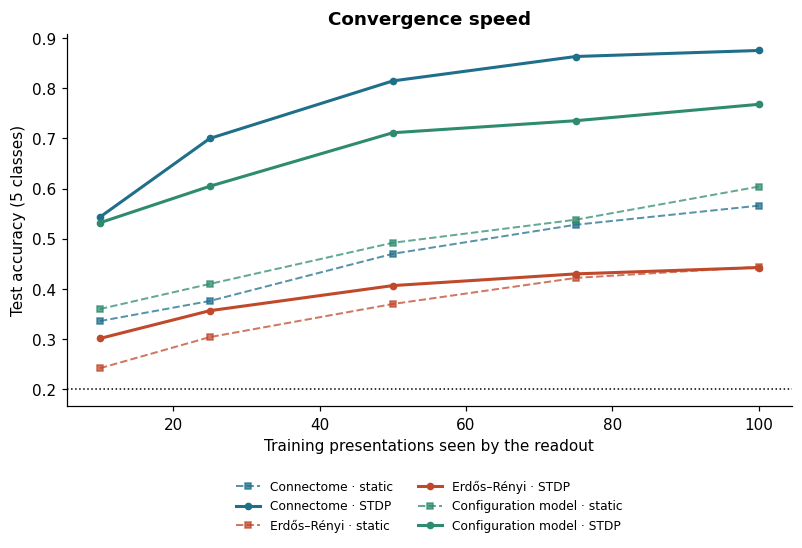

Presentations needed to pass 90 % of the final accuracy:
  Connectome                 static      75 of 100
  Connectome                 STDP        50 of 100
  Erdős–Rényi                static      75 of 100
  Erdős–Rényi                STDP        50 of 100
  Configuration model        static     100 of 100
  Configuration model        STDP        50 of 100


In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for t in TOPOS:
    for stdp, ls, alpha in [(False,'--',.75), (True,'-',1.0)]:
        sub = F[(F.topology==t)&(F.stdp==stdp)]
        curves = [c for c in sub.convergence_curve if c]
        if not curves: continue
        ks = [p[0] for p in curves[0]]
        m = np.array([[p[1] for p in c] for c in curves]).mean(axis=0)
        ax.plot(ks, m, ls, color=DARK[t], lw=2 if stdp else 1.3, alpha=alpha,
                marker='o' if stdp else 's', ms=4,
                label=f'{NAME[t]} · {"STDP" if stdp else "static"}')
ax.axhline(CHANCE, color='k', ls=':', lw=1)
ax.set_xlabel('Training presentations seen by the readout')
ax.set_ylabel('Test accuracy (5 classes)'); ax.legend(fontsize=8, frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.17))
ax.set_title('Convergence speed')
fig.savefig(FIGURES/'05-readout-convergence.png'); plt.show()

print('Presentations needed to pass 90 % of the final accuracy:')
for t in TOPOS:
    for stdp in [False, True]:
        sub = F[(F.topology==t)&(F.stdp==stdp)]
        curves = [c for c in sub.convergence_curve if c]
        if not curves: continue
        ks = [p[0] for p in curves[0]]
        m = np.array([[p[1] for p in c] for c in curves]).mean(axis=0)
        target = 0.9*m[-1]
        k = next((ks[i] for i, v in enumerate(m) if v >= target), ks[-1])
        print(f'  {NAME[t]:26s} {"STDP" if stdp else "static":10s} {k:3d} of {ks[-1]}')

The connectome with STDP is ahead at every point of the curve. With only 10 presentations it already reaches 0.543, more than either Erdős–Rényi network reaches with all 100 (0.444 static, 0.443 with STDP). It then climbs to 0.700, 0.815, 0.863 and 0.875. The configuration model with STDP starts almost level with it, at 0.532, and stays below from then on.

The printed column is the 90 % indicator. The three plastic arms cross it at 50 presentations. Among the static arms the connectome and Erdős–Rényi need 75 and the configuration model all 100. Read with the caution above, this column says little about learning speed, and the curves say more.

## 4. Spike efficiency

On event-driven neuromorphic chips such as Loihi, energy is spent only when spikes occur (Davies et al., 2018; Schuman et al., 2022). What matters is therefore not only being right but what being right costs. The cell reports the spikes the network fires per correct classification and plots accuracy against that cost.

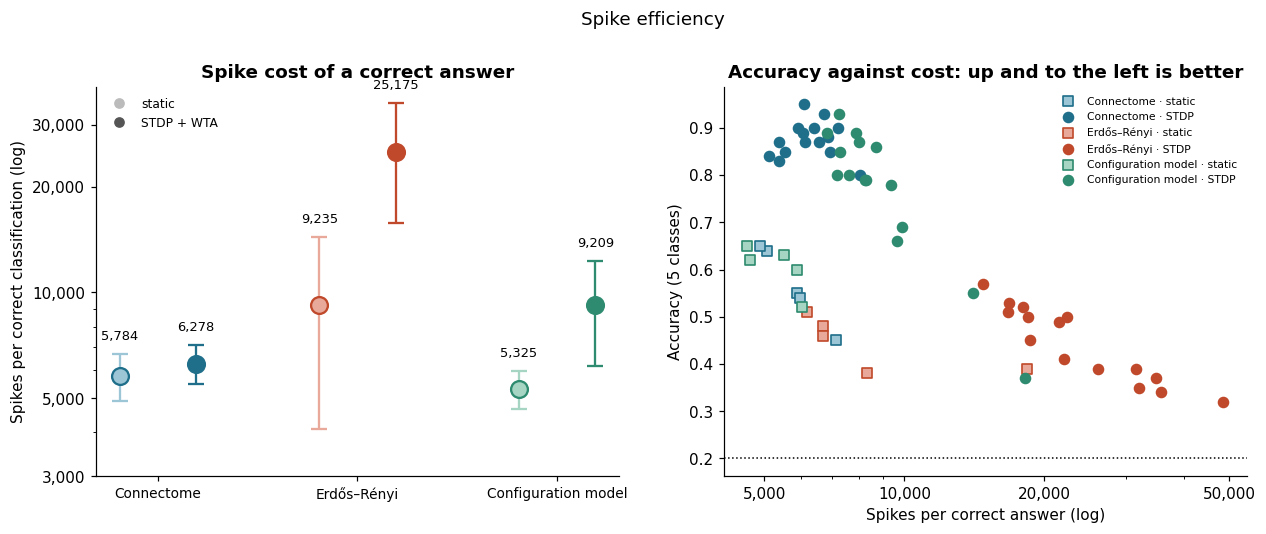

Spikes per correct answer (mean ± standard deviation):
  Connectome                 static         5,784 ±     886
  Connectome                 STDP           6,278 ±     790
  Erdős–Rényi                static         9,235 ±   5,154
  Erdős–Rényi                STDP          25,175 ±   9,453
  Configuration model        static         5,325 ±     662
  Configuration model        STDP           9,209 ±   3,052

With plasticity, the random network spends 4.0 times more spikes per correct answer
than the connectome, and reaches half its accuracy.


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.6))
pos, labels = [], []
for i, t in enumerate(TOPOS):
    for k, stdp in enumerate([False, True]):
        v = F[(F.topology==t)&(F.stdp==stdp)].spikes_per_correct
        p = i*1.1 + k*0.42
        ax[0].errorbar(p, v.mean(), yerr=v.std(), fmt='o', ms=11, capsize=5,
                       color=(LIGHT if not stdp else DARK)[t],
                       markeredgecolor=DARK[t], markeredgewidth=1.5)
        ax[0].text(p, (v.mean()+v.std())*1.1, f'{v.mean():,.0f}', ha='center', fontsize=8.5)
        pos.append(p); labels.append('')
ax[0].set_yscale('log')
ax[0].set_yticks([3000, 5000, 10000, 20000, 30000], ['3,000', '5,000', '10,000', '20,000', '30,000'])
ax[0].set_xticks([i*1.1+0.21 for i in range(3)])
ax[0].set_xticklabels([NAME[t] for t in TOPOS], fontsize=9)
ax[0].set_ylabel('Spikes per correct classification (log)')
ax[0].set_title('Spike cost of a correct answer')
ax[0].legend(handles=[Line2D([],[],marker='o',ls='',color='#BBBBBB',label='static'),
                      Line2D([],[],marker='o',ls='',color='#555555',label='STDP + WTA')],
             fontsize=8, frameon=False, loc='upper left')

for t in TOPOS:
    for stdp, mk in [(False,'s'), (True,'o')]:
        sub = F[(F.topology==t)&(F.stdp==stdp)]
        ax[1].scatter(sub.spikes_per_correct, sub.accuracy, s=42, marker=mk,
                      color=(LIGHT if not stdp else DARK)[t], edgecolor=DARK[t], linewidth=1.1,
                      label=f'{NAME[t]} · {"STDP" if stdp else "static"}')
ax[1].axhline(CHANCE, color='k', ls=':', lw=1)
ax[1].set_xscale('log'); ax[1].set_xlabel('Spikes per correct answer (log)')
ax[1].set_xticks([5000, 10000, 20000, 50000], ['5,000', '10,000', '20,000', '50,000'])
ax[1].set_ylabel('Accuracy (5 classes)'); ax[1].legend(fontsize=7, frameon=False, loc='upper right')
ax[1].set_title('Accuracy against cost: up and to the left is better')
fig.suptitle('Spike efficiency', y=1.03)
fig.savefig(FIGURES/'05-spike-efficiency.png'); plt.show()

print('Spikes per correct answer (mean ± standard deviation):')
for t in TOPOS:
    for stdp in [False, True]:
        v = F[(F.topology==t)&(F.stdp==stdp)].spikes_per_correct
        print(f'  {NAME[t]:26s} {"STDP" if stdp else "static":10s}'
              + f' {v.mean():9,.0f} ± {v.std():7,.0f}')
r = F[(F.topology=="er")&(F.stdp)].spikes_per_correct.mean() / \
    F[(F.topology=="connectome")&(F.stdp)].spikes_per_correct.mean()
print(f'\nWith plasticity, the random network spends {r:.1f} times more spikes per correct answer')
print('than the connectome, and reaches half its accuracy.')

The left panel shows the spikes per correct answer on a logarithmic axis, mean ± standard deviation across seeds. The right panel has one point per run, accuracy against cost, so the best networks sit at the top left.

Among the arms with plasticity the connectome is by far the most efficient. It needs 6,278 ± 790 spikes per correct answer. Erdős–Rényi with the same plasticity needs 25,175 ± 9,453, which is 4.0 times more, for about half the accuracy. Against the configuration model with STDP (9,209 ± 3,052) the connectome is more accurate and spends 31.8 % fewer spikes.

The static connectome (5,784) and the static configuration model (5,325) spend fewer spikes than the connectome with STDP, but they are far less accurate. Static Erdős–Rényi is not cheaper at all (9,235). On the right panel the dark blue cloud of the connectome with STDP holds the best balance between accuracy and cost.

These are spike counts compared between spiking networks, not an energy comparison with conventional networks. Phase 04 makes that comparison, and it comes out against the spiking networks (see the [comparison with conventional networks](../04-modeling/results.md#11-comparison-with-conventional-networks)).

## 5. Latency: accuracy against integration time

How much response time does the readout need to decide? The integration window is the axis of difficulty of the task. It is also the latency that matters for a low-power device, where a shorter window means fewer spikes, less energy and less delay. The cell plots five-class accuracy against windows of 25, 50, 100, 250 and 500 ms. For the plastic arms the shaded bands show the spread across seeds (± one standard deviation, population formula).

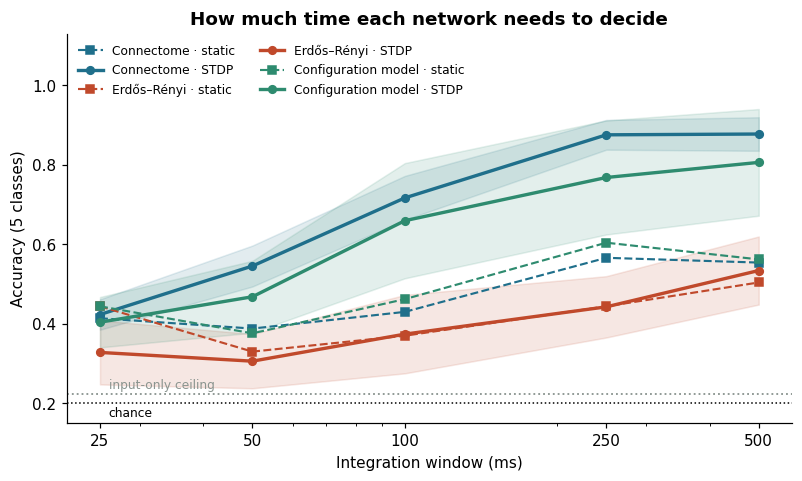

arm                                 25 ms      50 ms     100 ms     250 ms     500 ms
Connectome · static                 0.414      0.388      0.430      0.566      0.554
Connectome · STDP                   0.423      0.545      0.717      0.875      0.877
Erdős–Rényi · static                0.444      0.330      0.370      0.444      0.504
Erdős–Rényi · STDP                  0.328      0.306      0.374      0.443      0.534
Configuration model · static        0.444      0.376      0.462      0.604      0.562
Configuration model · STDP          0.404      0.468      0.659      0.768      0.806


In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for t in TOPOS:
    for stdp, ls in [(False,'--'), (True,'-')]:
        sub = F[(F.topology==t)&(F.stdp==stdp)]
        cur = np.array([list(r.values()) for r in sub.accuracy_vs_window])
        m, s = cur.mean(axis=0), cur.std(axis=0)
        ax.plot(WINDOWS_MS, m, ls, color=DARK[t], lw=2.2 if stdp else 1.4,
                marker='o' if stdp else 's', ms=5,
                label=f'{NAME[t]} · {"STDP" if stdp else "static"}')
        if stdp:
            ax.fill_between(WINDOWS_MS, m-s, m+s, color=DARK[t], alpha=.13)
ax.axhline(CHANCE, color='k', ls=':', lw=1); ax.axhline(CEILING, color=GRAY, ls=':', lw=1.2)
ax.text(26, CHANCE-0.008, 'chance', va='top', fontsize=8)
ax.text(26, CEILING+0.008, 'input-only ceiling', va='bottom', fontsize=8, color=GRAY)
ax.set_xscale('log'); ax.set_xticks(WINDOWS_MS); ax.set_xticklabels(WINDOWS_MS)
ax.set_xlabel('Integration window (ms)'); ax.set_ylabel('Accuracy (5 classes)')
ax.set_ylim(0.15, 1.13)
ax.legend(fontsize=8, frameon=False, ncol=2, loc='upper left')
ax.set_title('How much time each network needs to decide')
fig.savefig(FIGURES/'05-latency-integration-window.png'); plt.show()

print(f'{"arm":30s}' + ''.join(f'{v:>8} ms' for v in WINDOWS_MS))
for t in TOPOS:
    for stdp in [False, True]:
        sub = F[(F.topology==t)&(F.stdp==stdp)]
        m = np.array([list(r.values()) for r in sub.accuracy_vs_window]).mean(axis=0)
        label = f'{NAME[t]} · {"STDP" if stdp else "static"}'
        print(f'{label:30s}' + ''.join(f'{x:11.3f}' for x in m))

Two curves rise steadily, those of the connectome and of the configuration model, both with plasticity. Only the connectome levels off within the range. It goes from 0.423 at 25 ms to 0.875 at 250 ms and gains almost nothing with twice the time (0.877 at 500 ms). The configuration model is still rising at the end, from 0.768 at 250 ms to 0.806 at 500 ms. A plausible mechanical reading is that a 250 ms window holds between about four song pulses (at an interval of 65 ms) and ten (at 25 ms), enough evidence to estimate a rhythm.

The other four curves dip between 25 and 50 ms and then rise more slowly, ending between 0.504 and 0.562 at 500 ms. At 25 ms every arm sits between 0.328 and 0.444, well above chance, and the order between arms there says little. From 50 ms on, the connectome with STDP leads the whole curve.

## 6. Difficulty gradient

Here the readout chooses between **two** songs, not among five, so the chance level of this section is **0.500**. Its numbers are pairwise accuracies and are not compared with the five-class accuracies of Sections 1 and 5. The five pairs come from the same responses, by restricting the readout to two classes, with no new simulation.

What orders the pairs is not the difference in milliseconds but the **relative** difference. `35 vs 45` and `45 vs 55` are both 10 ms apart. Yet 10 ms is 29 % of a 35 ms interval and only 22 % of a 45 ms one, so the second pair should be harder. This is Weber's law, by which what is registered of a change is its proportion and not its absolute size (Gibbon, 1977). The series runs from 160 % for `25 vs 65` down to 22 %.

The pair **35 vs 55 ms**, highlighted in the figure, sets a song typical of *D. melanogaster*, whose interval is about 34 ms, against one in the range reported for *D. simulans*, 50 to 65 ms (Bennet-Clark & Ewing, 1969; Deutsch et al., 2019).

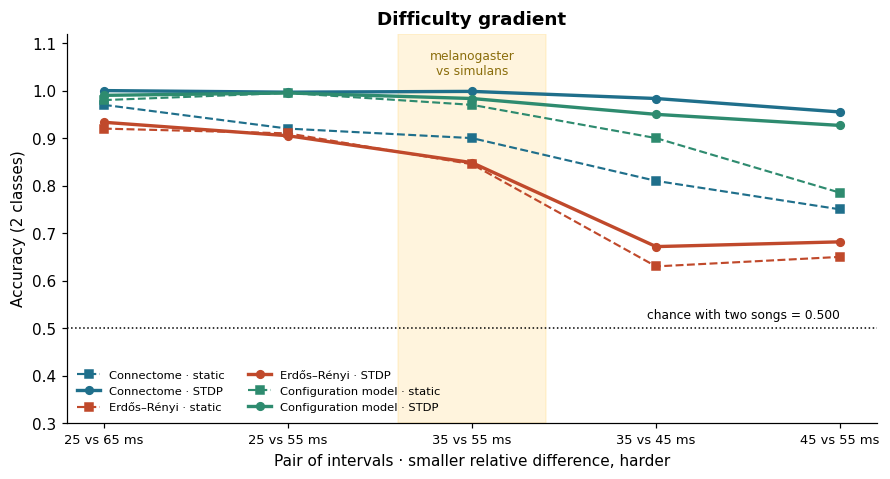

,25 vs 65 ms,25 vs 55 ms,35 vs 55 ms,35 vs 45 ms,45 vs 55 ms
network,,,,,
Connectome · static,0.970,0.920,0.900,0.810,0.750
Connectome · STDP,1.000,0.997,0.998,0.983,0.955
Erdős–Rényi · static,0.920,0.910,0.845,0.630,0.650
Erdős–Rényi · STDP,0.933,0.905,0.848,0.672,0.682
Configuration model · static,0.980,0.995,0.970,0.900,0.785
Configuration model · STDP,0.990,0.995,0.983,0.950,0.927


In [9]:
names = [p[0] for p in PAIRS]
labels = [f'{p[1]} vs {p[2]} ms' for p in PAIRS]
fig, ax = plt.subplots(figsize=(9.5, 4.6))
x = np.arange(len(names))
for t in TOPOS:
    for stdp, ls in [(False,'--'), (True,'-')]:
        sub = F[(F.topology==t)&(F.stdp==stdp)]
        m = [np.mean([p[n] for p in sub.pair_accuracy]) for n in names]
        ax.plot(x, m, ls, marker='o' if stdp else 's', ms=5, color=DARK[t],
                lw=2.2 if stdp else 1.4,
                label=f'{NAME[t]} · {"STDP" if stdp else "static"}')
ax.axhline(.5, color='k', ls=':', lw=1)
ax.text(len(names)-1, .515, 'chance with two songs = 0.500', fontsize=8, va='bottom', ha='right',
        bbox=dict(fc='white', ec='none', alpha=.85, pad=1.5))
ax.axvspan(1.6, 2.4, color='#FFD166', alpha=.22)
ax.text(2, 1.035, 'melanogaster\nvs simulans', ha='center', fontsize=8, color='#8A6D0B')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylim(.30, 1.12); ax.set_ylabel('Accuracy (2 classes)')
ax.set_xlabel('Pair of intervals · smaller relative difference, harder'); ax.legend(fontsize=7.5, frameon=False, ncol=2, loc='lower left')
ax.set_title('Difficulty gradient')
fig.savefig(FIGURES/'05-difficulty-gradient.png'); plt.show()

rows = []
for t in TOPOS:
    for stdp in [False, True]:
        sub = F[(F.topology==t)&(F.stdp==stdp)]
        f = {'network': f'{NAME[t]} · {"STDP" if stdp else "static"}'}
        for n, e in zip(names, labels):
            f[e] = round(float(np.mean([p[n] for p in sub.pair_accuracy])), 3)
        rows.append(f)
pd.DataFrame(rows).set_index('network')

The connectome with STDP comes first on all five pairs, from 1.000 on the easiest to 0.955 on the hardest. It tells the two species' songs apart (35 vs 55 ms) with an accuracy of 0.998. On the hardest pair, 45 vs 55 ms, it keeps 0.955 where Erdős–Rényi with STDP falls to 0.682.

In four of the six arms the hardest pair comes out worse than `35 vs 45`, as the relative difference predicts. The two Erdős–Rényi arms are the exception. Their two hard pairs are close to each other, 0.630 and 0.650 static and 0.672 and 0.682 with STDP. All these values are on the two-class scale, with chance at 0.500.

## 7. Selectivity and coverage of the representation

**Selectivity** measures whether the response concentrates on a few neurons or spreads over the whole population. It is the population sparseness $S = [1 - (\sum r/n)^2 / \sum (r^2/n)] / (1 - 1/n)$, where $r$ are the responses of the $n$ readout neurons to one presentation. This is the normalized Treves–Rolls measure (Treves & Rolls, 1991; Vinje & Gallant, 2000) computed across neurons (Willmore & Tolhurst, 2001). It is 0 when all neurons respond equally and 1 when a single neuron responds. **Coverage** is the percentage of readout neurons that fire at least once during a presentation. Both describe *how* each network represents the song, beyond whether it gets it right.

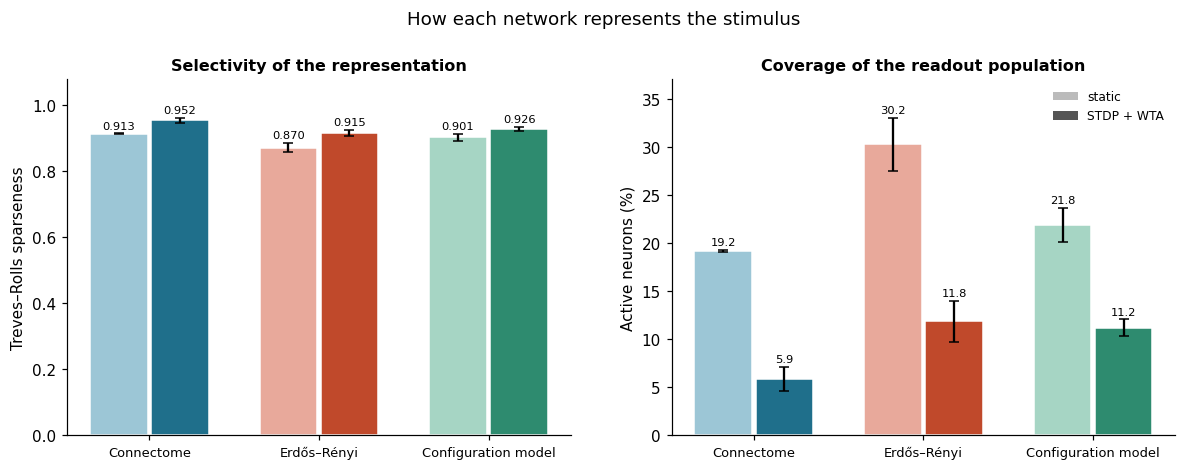

,selectivity,coverage
network,,
"Configuration model, static",0.901,21.847
Configuration model + STDP,0.926,11.176
"Connectome, static",0.913,19.155
Connectome + STDP,0.952,5.851
"Erdős–Rényi, static",0.870,30.237
Erdős–Rényi + STDP,0.915,11.834


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for j, (col, title, label, fmt) in enumerate([
        ('selectivity', 'Selectivity of the representation', 'Treves–Rolls sparseness', '{:.3f}'),
        ('coverage_pct', 'Coverage of the readout population', 'Active neurons (%)', '{:.1f}')]):
    for i, t in enumerate(TOPOS):
        for k, stdp in enumerate([False, True]):
            v = F[(F.topology==t)&(F.stdp==stdp)][col]
            ax[j].bar(i + (k-0.5)*0.36, v.mean(), 0.34, yerr=v.std(), capsize=3,
                      color=(LIGHT if not stdp else DARK)[t], edgecolor='white', linewidth=1)
            ax[j].annotate(fmt.format(v.mean()), (i + (k-0.5)*0.36, v.mean()+v.std()),
                           xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7.5)
    ax[j].set_xticks(range(3)); ax[j].set_xticklabels([NAME[t] for t in TOPOS], fontsize=8.5)
    ax[j].set_ylabel(label); ax[j].set_title(title, fontsize=10.5); ax[j].margins(y=.12)
ax[1].legend(handles=[Patch(facecolor='#BBBBBB', label='static'),
                      Patch(facecolor='#555555', label='STDP + WTA')],
             fontsize=8, frameon=False, loc='upper right')
fig.suptitle('How each network represents the stimulus', y=1.03)
fig.savefig(FIGURES/'05-representation.png'); plt.show()

rep = (F.groupby(['topology','stdp'])[['selectivity','coverage_pct']].mean()
         .round(3).reset_index().rename(columns={'coverage_pct':'coverage'}))
rep['network'] = rep.topology.map(NAME) + rep.stdp.map({True:' + STDP', False:', static'})
rep[['network','selectivity','coverage']].set_index('network')

Plasticity raises selectivity in all three wirings and lowers coverage. The connectome with STDP has the highest selectivity (0.952) and the lowest coverage of the six arms (5.851 %). On average only about 65 of its 1,116 readout neurons fire during a song.

Those two numbers go together. A response spread evenly over that small fraction of neurons would already have a selectivity of about 0.94, so most of the high selectivity reflects how few neurons respond. Selectivity alone therefore does not prove that the neurons have specialized. What makes this small group worth noting is that it is also the one that classifies best (Section 1), at the lowest spike cost among the plastic arms (Section 4). The network as a whole is not silent, since its mean rate is 17.7 Hz. Its activity is concentrated.

The table repeats the values of Section 1, rounded to three decimals.

## 8. Weight stability after learning

Two indicators tell whether plasticity converged or left the network in a transient state. The mean weight change |Δw| says how far learning moved the weights, and the drift of the mean weight over the last 20 % of training says whether they were still moving at the end. A small drift means that learning settled.

                         dw   dw_sd   drift  drift_sd
Configuration model  0.8582  0.1531  0.0146    0.0068
Connectome           0.5429  0.0995  0.0124    0.0061
Erdős–Rényi          0.6016  0.0648  0.0252    0.0160

All three networks change their weights substantially, but only in the
connectome does that change bring a significant gain in accuracy. The
biological network does not learn more: it learns better.


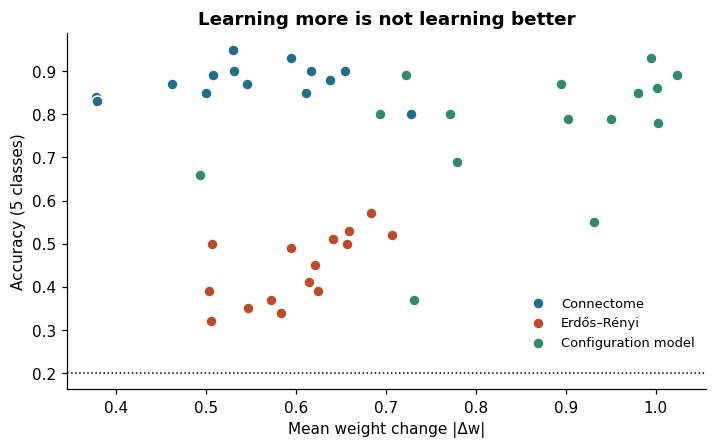

In [11]:
d = F[F.stdp]
t_ = d.groupby('topology').agg(dw=('mean_dw','mean'), dw_sd=('mean_dw','std'),
                               drift=('weight_drift','mean'),
                               drift_sd=('weight_drift','std')).round(4)
t_.index = [NAME[i] for i in t_.index]
print(t_.to_string())
print()
print('All three networks change their weights substantially, but only in the')
print('connectome does that change bring a significant gain in accuracy. The')
print('biological network does not learn more: it learns better.')

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for t in TOPOS:
    s = F[(F.topology==t)&(F.stdp)]
    ax.scatter(s.mean_dw, s.accuracy, s=52, color=DARK[t], edgecolor='white',
               linewidth=1, label=NAME[t])
ax.axhline(CHANCE, color='k', ls=':', lw=1)
ax.set_xlabel('Mean weight change |Δw|'); ax.set_ylabel('Accuracy (5 classes)')
ax.legend(fontsize=8.5, frameon=False, loc='lower right', bbox_to_anchor=(1, 0.08))
ax.set_title('Learning more is not learning better')
fig.savefig(FIGURES/'05-weight-change-vs-accuracy.png'); plt.show()

The table lists the arms with STDP in alphabetical order. The connectome moves its weights the least (|Δw| = 0.5429 ± 0.0995) and ends with the smallest drift (0.0124 ± 0.0061). Erdős–Rényi moves a little more (0.6016) and ends with about twice that drift (0.0252). The configuration model moves the most (0.8582) for a drift close to the connectome's (0.0146). All three settle.

The figure puts accuracy against |Δw|, one point per seed. The connectome and Erdős–Rényi move their weights by similar amounts but sit at very different accuracies, and the configuration model spreads along both axes. How much the weights move does not predict accuracy; the wiring the rule works on does.

## 9. Robustness of the result

Before concluding we have to rule out that the advantage depends on one particular design decision. The cell checks three of them.

1. **The seed**, with the fifteen independent repetitions of the connectome with STDP.
2. **The mapping of filterbank channels onto input neurons**, with four variants and five seeds each. The default mapping is anchored to anatomy, with JO-B neurons on the low channels and JO-A neurons on the high ones. The others are its inverse, the order of FlyWire identifiers (`root_id`) and a random assignment.
3. **The contact threshold**, by rebuilding the subgraph at thresholds of 1, 3, 5 and 10 contacts and recalibrating the operating point at each one, with three seeds per arm (`04-modeling/outputs/threshold_sweep.json`).

In [12]:
print('1) SPREAD ACROSS SEEDS (connectome + STDP)')
v = arm('connectome', True)
print(f'   n = {len(v)}  ·  mean {v.mean():.3f}  ·  standard deviation {v.std(ddof=1):.3f}  '
      f'·  range [{v.min():.3f}, {v.max():.3f}]')
print(f'   every seed beats the input-only ceiling ({CEILING:.3f}): '
      f'{bool((v > CEILING).all())}')

print('\n2) CHANNEL-TO-NEURON MAPPING (connectome)')
for mode in ['subtype','subtype_inverted','root_id','random']:
    for plasticity_tag in ['static','stdp']:
        s = ALL_RUNS[ALL_RUNS.arm==f'mapping_{mode}_{plasticity_tag}'].accuracy
        if len(s):
            print(f'   {mode:20s} {plasticity_tag:9s} {s.mean():.3f} ± {s.std():.3f}')
print('   With all four mappings the network stays far above the input-only ceiling:')
print('   the result is not an artifact of a lucky assignment.')

u = Path('..')/'04-modeling'/'outputs'/'threshold_sweep.json'
if u.exists():
    print('\n3) CONTACT THRESHOLD PER CONNECTION')
    b = pd.DataFrame(json.loads(u.read_text()))
    piv = b.pivot_table(index='threshold', columns=['topology','stdp'], values='accuracy')
    print(f'   {"threshold":>9}{"connectome+STDP":>17}{"ER+STDP":>11}{"advantage":>11}')
    for uu in sorted(b.threshold.unique()):
        c = b[(b.threshold==uu)&(b.topology=='connectome')&(b.stdp)].accuracy.mean()
        e = b[(b.threshold==uu)&(b.topology=='er')&(b.stdp)].accuracy.mean()
        mark = '  <- adopted' if uu==5 else ''
        print(f'   {uu:>9}{c:17.3f}{e:11.3f}{c-e:+11.3f}{mark}')
    print('   The advantage of the connectome holds across the whole usable range.')

1) SPREAD ACROSS SEEDS (connectome + STDP)
   n = 15  ·  mean 0.875  ·  standard deviation 0.039  ·  range [0.800, 0.950]
   every seed beats the input-only ceiling (0.223): True

2) CHANNEL-TO-NEURON MAPPING (connectome)
   subtype              static    0.566 ± 0.082
   subtype              stdp      0.880 ± 0.048
   subtype_inverted     static    0.758 ± 0.044
   subtype_inverted     stdp      0.900 ± 0.040
   root_id              static    0.676 ± 0.044
   root_id              stdp      0.892 ± 0.016
   random               static    0.736 ± 0.045
   random               stdp      0.920 ± 0.029
   With all four mappings the network stays far above the input-only ceiling:
   the result is not an artifact of a lucky assignment.

3) CONTACT THRESHOLD PER CONNECTION
   threshold  connectome+STDP    ER+STDP  advantage
           1            0.727      0.183     +0.543
           3            0.903      0.223     +0.680
           5            0.863      0.467     +0.397  <- adopted
   

Over fifteen seeds the connectome with STDP averages 0.875 with a standard deviation of 0.039, from 0.800 to 0.950, and every seed beats the input-only ceiling.

With all four channel mappings the connectome with plasticity stays between 0.880 and 0.920. The anchored mapping used in the main results is the least favorable of the four for the accuracy of the connectome, with and without plasticity. Only the connectome was run with the four mappings, so these runs test its accuracy, not its advantage over the controls, which ran only with the anchored mapping. The anchored row with STDP is the main arm on its first five seeds, which the code reproduces exactly. That is why it reads 0.880 here against 0.875 over fifteen seeds.

The advantage of the connectome over Erdős–Rényi with STDP holds at thresholds 3, 5 and 10 (+0.680, +0.397 and +0.370). This sweep compares the connectome only with Erdős–Rényi, with three seeds per arm and no statistical test. The row for threshold 1 (+0.543) is not comparable with the others. At that threshold the random network could not be brought down to the common operating point (see [Robustness to the contact threshold](../04-modeling/results.md#10-robustness-to-the-contact-threshold) in the phase 04 results). At threshold 5 the sweep gives 0.863 for the connectome, a mean over three seeds; on those same three seeds the main experiment gives 0.863 too.

## 10. Verdict

The next cell gathers the numbers in one place, so that the conclusion can be read directly and checked. The arms are sorted by mean accuracy, and each one is contrasted with the best by a paired t-test.

In [13]:
print('='*74)
print('COMPARATIVE EVALUATION: VERDICT'.center(74))
print('='*74)
print(f'\nTask: tell apart {len(IPIS)} inter-pulse intervals of the courtship song')
print(f'Chance = {CHANCE:.3f}   ·   input-only ceiling = {CEILING:.3f}')
print(f'Design: 3 topologies × 2 plasticity conditions, operating point matched at '
      f'{OP["target_hz"]:.0f} Hz\n')
print(f'{"arm":30s}{"accuracy":>14}{"spikes/correct":>16}{"selectivity":>14}')
order = sorted([(t, s) for t in TOPOS for s in [False, True]],
               key=lambda k: -arm(k[0], k[1]).mean())
for t, stdp in order:
    s_ = F[(F.topology==t)&(F.stdp==stdp)]
    label = f'{NAME[t]} · {"STDP" if stdp else "static"}'
    print(f'{label:30s}{s_.accuracy.mean():8.3f}±{s_.accuracy.std():5.3f}'
          f'{s_.spikes_per_correct.mean():16,.0f}{s_.selectivity.mean():14.3f}')

g_t, g_s = order[0]
print(f'\nBEST: {NAME[g_t]} · {"STDP + WTA" if g_s else "static"}')
print('\nContrasts against the best arm (paired t-test by seed):')
ref = arm(g_t, g_s)
for t, stdp in order[1:]:
    o = arm(t, stdp); n = min(len(ref), len(o))
    tt, p = stats.ttest_rel(ref[:n], o[:n])
    label = f'{NAME[t]} · {"STDP" if stdp else "static"}'
    mark = 'significant' if p < 0.05 else 'not significant'
    print(f'  vs {label:30s} Δ = {ref.mean()-o.mean():+.3f}   p = {p:.5f}   {mark}')

print('\nEffect of plasticity by topology:')
for t in TOPOS:
    dd, pp = delta[t]
    print(f'  {NAME[t]:26s} Δ = {dd:+.3f}   p = {pp:.5f}   '
          f'{"improves" if (pp<0.05 and dd>0) else "no significant effect"}')

pair_acc = F[(F.topology=='connectome')&(F.stdp)].pair_accuracy
print(f'\nPair 35 vs 55 ms (melanogaster-like vs simulans-like song, two classes, '
      f'chance 0.500): '
      f'{np.mean([p["Medium"] for p in pair_acc]):.3f}')
print('='*74)

                     COMPARATIVE EVALUATION: VERDICT                      

Task: tell apart 5 inter-pulse intervals of the courtship song
Chance = 0.200   ·   input-only ceiling = 0.223
Design: 3 topologies × 2 plasticity conditions, operating point matched at 10 Hz

arm                                 accuracy  spikes/correct   selectivity
Connectome · STDP                0.875±0.039           6,278         0.952
Configuration model · STDP       0.768±0.148           9,209         0.926
Configuration model · static     0.604±0.050           5,325         0.901
Connectome · static              0.566±0.082           5,784         0.913
Erdős–Rényi · static             0.444±0.057           9,235         0.870
Erdős–Rényi · STDP               0.443±0.080          25,175         0.915

BEST: Connectome · STDP + WTA

Contrasts against the best arm (paired t-test by seed):
  vs Configuration model · STDP     Δ = +0.107   p = 0.01671   significant
  vs Configuration model · static   Δ = +0.

## 11. Conclusions

**The connectome with STDP is the best of the six arms on the auditory task.** It leads in accuracy and representation, and among the arms with plasticity it is also the cheapest in spikes.

1. **Accuracy.** It reaches 0.875 ± 0.039 over fifteen seeds and beats the random network and the control that keeps the degree sequence, both with statistical significance and large effect sizes (d = 7.14 and d = 1.02).
2. **Spike efficiency.** It reaches that accuracy with about a quarter of the spikes per correct answer that the random network with the same plasticity needs (6,278 against 25,175).
3. **Representation.** Its response is the most selective and the most concentrated of the six arms, carried by about 6 % of the readout neurons. Selectivity alone does not prove specialization, but this small group is also the one that classifies best.

It also brings a finding that was not in the starting hypothesis. **Plasticity pays off significantly only on the biological wiring.** The same rule, with the same parameters, is applied to networks of identical size, density and weight distribution. It significantly improves the connectome and does nothing for the random network. Its gain on the configuration model is about half as large and not significant, and the direct test of the interaction is significant against Erdős–Rényi but not against the configuration model (Section 2). The wiring does more than carry the signal. It decides whether local learning finds a useful solution.

The accuracy of the connectome holds across the sources of variation we checked (seed, channel mapping and contact threshold), within the limits of Section 9, and it is always measured against a known input-only ceiling. The accuracy reported is computed by the network, not information that arrived already solved.

### Scope

This notebook compares **the three spiking networks with one another**, which is what our evaluation objective asks. The comparison with conventional, second-generation neural networks is in the [phase 04 results](../04-modeling/results.md#11-comparison-with-conventional-networks), and it marks how far the conclusions reach. On this task a linear classifier is cheaper, because a subgraph of 1,239 neurons is oversized for a five-class problem. The energy advantage of spiking networks is motivation taken from the literature (Roy et al., 2019; Schuman et al., 2022), not a result of this work.

The main limitations are listed in the [results of this phase](results.md#scope-and-limitations). The task is a proxy, the operating point is matched before learning, the readout is linear and the songs are synthetic. Plasticity includes the WTA layer, and the p-values are not corrected for multiple comparisons.

## 12. Next steps

What these results suggest for small, battery-powered devices, and the plan that follows from them, are in the [Next steps](results.md#next-steps-from-the-fly-to-low-power-devices) section of the results of this phase. None of it changes the conclusions above. The plan describes how an energy advantage could be tested, not a result we obtained.

The numbers of this notebook and their reading are gathered in the [results of this phase](results.md). How the evaluation took shape, and what changed along the way, is in the [research log](research-log.md).

## References

- Baker, C. A., McKellar, C., Pang, R., Nern, A., Dorkenwald, S., Pacheco, D. A., Eckstein, N., Funke, J., Dickson, B. J., & Murthy, M. (2022). Neural network organization for courtship-song feature detection in *Drosophila*. *Current Biology, 32*(15), 3317–3333.e7. https://doi.org/10.1016/j.cub.2022.06.019
- Bennet-Clark, H. C., & Ewing, A. W. (1969). Pulse interval as a critical parameter in the courtship song of *Drosophila melanogaster*. *Animal Behaviour, 17*(4), 755–759. https://doi.org/10.1016/S0003-3472(69)80023-0
- Cohen, J. (2013). *Statistical power analysis for the behavioral sciences* (2nd ed.). Routledge. https://doi.org/10.4324/9780203771587 (Original work published 1988)
- Davies, M., Srinivasa, N., Lin, T.-H., Chinya, G., Cao, Y., Choday, S. H., Dimou, G., Joshi, P., Imam, N., Jain, S., Liao, Y., Lin, C.-K., Lines, A., Liu, R., Mathaikutty, D., McCoy, S., Paul, A., Tse, J., Venkataramanan, G., . . . Wang, H. (2018). Loihi: A neuromorphic manycore processor with on-chip learning. *IEEE Micro, 38*(1), 82–99. https://doi.org/10.1109/MM.2018.112130359
- Deutsch, D., Clemens, J., Thiberge, S. Y., Guan, G., & Murthy, M. (2019). Shared song detector neurons in *Drosophila* male and female brains drive sex-specific behaviors. *Current Biology, 29*(19), 3200–3215.e5. https://doi.org/10.1016/j.cub.2019.08.008
- Dhiman, N. (2026). *Topological sensitivity in connectome-constrained neural networks* (arXiv:2604.04033) [Preprint]. arXiv. https://doi.org/10.48550/arXiv.2604.04033
- Dorkenwald, S., Matsliah, A., Sterling, A. R., Schlegel, P., Yu, S.-c., McKellar, C. E., Lin, A., Costa, M., Eichler, K., Yin, Y., Silversmith, W., Schneider-Mizell, C., Jordan, C. S., Brittain, D., Halageri, A., Kuehner, K., Ogedengbe, O., Morey, R., Gager, J., . . . The FlyWire Consortium. (2024). Neuronal wiring diagram of an adult brain. *Nature, 634*(8032), 124–138. https://doi.org/10.1038/s41586-024-07558-y
- Erdős, P., & Rényi, A. (1959). On random graphs I. *Publicationes Mathematicae Debrecen, 6*(3–4), 290–297. https://doi.org/10.5486/PMD.1959.6.3-4.12
- Gibbon, J. (1977). Scalar expectancy theory and Weber’s law in animal timing. *Psychological Review, 84*(3), 279–325. https://doi.org/10.1037/0033-295X.84.3.279
- Molloy, M., & Reed, B. (1995). A critical point for random graphs with a given degree sequence. *Random Structures & Algorithms, 6*(2–3), 161–180. https://doi.org/10.1002/rsa.3240060204
- Newman, M. E. J., Strogatz, S. H., & Watts, D. J. (2001). Random graphs with arbitrary degree distributions and their applications. *Physical Review E, 64*(2), Article 026118. https://doi.org/10.1103/PhysRevE.64.026118
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
- Roy, K., Jaiswal, A., & Panda, P. (2019). Towards spike-based machine intelligence with neuromorphic computing. *Nature, 575*(7784), 607–617. https://doi.org/10.1038/s41586-019-1677-2
- Schuman, C. D., Kulkarni, S. R., Parsa, M., Mitchell, J. P., Date, P., & Kay, B. (2022). Opportunities for neuromorphic computing algorithms and applications. *Nature Computational Science, 2*(1), 10–19. https://doi.org/10.1038/s43588-021-00184-y
- Song, S., Miller, K. D., & Abbott, L. F. (2000). Competitive Hebbian learning through spike-timing-dependent synaptic plasticity. *Nature Neuroscience, 3*(9), 919–926. https://doi.org/10.1038/78829
- Treves, A., & Rolls, E. T. (1991). What determines the capacity of autoassociative memories in the brain? *Network: Computation in Neural Systems, 2*(4), 371–397. https://doi.org/10.1088/0954-898X_2_4_004
- Vinje, W. E., & Gallant, J. L. (2000). Sparse coding and decorrelation in primary visual cortex during natural vision. *Science, 287*(5456), 1273–1276. https://doi.org/10.1126/science.287.5456.1273
- Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., . . . Vázquez-Baeza, Y. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2
- Willmore, B., & Tolhurst, D. J. (2001). Characterizing the sparseness of neural codes. *Network: Computation in Neural Systems, 12*(3), 255–270. https://doi.org/10.1080/net.12.3.255.270